In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, ops
import keras_hub
from keras.utils import pad_sequences

from datasets import load_dataset

from transformers import AutoTokenizer

In [130]:
ds = load_dataset("knkarthick/samsum")

In [131]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})


In [132]:
train_df = ds['train'].to_pandas()
val_df = ds['validation'].to_pandas()
test_df = ds['test'].to_pandas()

In [133]:
train_df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\nJ...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\nKim: Bad mood tbh, I was ...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\nSam: i...,"Sam is confused, because he overheard Rick com..."


In [134]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14731 entries, 0 to 14730
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        14731 non-null  object
 1   dialogue  14731 non-null  object
 2   summary   14731 non-null  object
dtypes: object(3)
memory usage: 345.4+ KB


In [135]:
train_df.isna().sum()

,0
id,0
dialogue,0
summary,0


In [136]:
train_df.duplicated().sum()

np.int64(0)

In [137]:
dialogue = train_df['dialogue'].tolist()
summary = train_df['summary'].tolist()

print(f'Number of rows in dialogue: {len(dialogue):,}')
print(f'Number of rows in summary: {len(summary):,}')
print('-' * 80)

for i in range(6):
    print(f'Dialogue:\n{dialogue[i]}\n' + '-' * 80 + f'\nSummary:\n{summary[i]}\n' + '-' * 80)
    # print('-' * 80)

Number of rows in dialogue: 14,731
Number of rows in summary: 14,731
--------------------------------------------------------------------------------
Dialogue:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)
--------------------------------------------------------------------------------
Summary:
Amanda baked cookies and will bring Jerry some tomorrow.
--------------------------------------------------------------------------------
Dialogue:
Olivia: Who are you voting for in this election? 
Oliver: Liberals as always.
Olivia: Me too!!
Oliver: Great
--------------------------------------------------------------------------------
Summary:
Olivia and Olivier are voting for liberals in this election. 
--------------------------------------------------------------------------------
Dialogue:
Tim: Hi, what's up?
Kim: Bad mood tbh, I was going to do lots of stuff but ended up procrastinating
Tim: What did you plan on doing?
Kim: Oh you know, uni st

In [138]:
t5_tokenizer = AutoTokenizer.from_pretrained("google-t5/t5-small")

In [139]:
print("Vocabulary size:", t5_tokenizer.vocab_size)
print("PAD token:", t5_tokenizer.pad_token, t5_tokenizer.pad_token_id)
print("EOS token:", t5_tokenizer.eos_token, t5_tokenizer.eos_token_id)
print("UNK token:", t5_tokenizer.unk_token, t5_tokenizer.unk_token_id)

Vocabulary size: 32100
PAD token: <pad> 0
EOS token: </s> 1
UNK token: <unk> 2


In [140]:
sample_dialogue = train_df["dialogue"].iloc[0]
sample_summary = train_df["summary"].iloc[0]

dialogue_tokens = t5_tokenizer.tokenize(sample_dialogue)
summary_tokens = t5_tokenizer.tokenize(sample_summary)

print("Original dialogue:\n", sample_dialogue)
print("\nDialogue tokens:\n", dialogue_tokens)

print("\nOriginal summary:\n", sample_summary)
print("\nSummary tokens:\n", summary_tokens)

Original dialogue:
 Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

Dialogue tokens:
 ['▁Amanda', ':', '▁I', '▁baked', '▁cookies', '.', '▁Do', '▁you', '▁want', '▁some', '?', '▁Jerry', ':', '▁Sure', '!', '▁Amanda', ':', '▁I', "'", 'll', '▁bring', '▁you', '▁tomorrow', '▁', ':', '-', ')']

Original summary:
 Amanda baked cookies and will bring Jerry some tomorrow.

Summary tokens:
 ['▁Amanda', '▁baked', '▁cookies', '▁and', '▁will', '▁bring', '▁Jerry', '▁some', '▁tomorrow', '.']


In [141]:
MAX_ENCODER_LENGTH = 384
MAX_DECODER_LENGTH = 80

PAD_ID = t5_tokenizer.pad_token_id  # 0
EOS_ID = t5_tokenizer.eos_token_id  # 1
START_ID = t5_tokenizer.pad_token_id  # 0


def prepare_t5_data(df):
    encoder_tokens = t5_tokenizer(
        df["dialogue"].tolist(),
        max_length=MAX_ENCODER_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )["input_ids"]

    summary_tokens = t5_tokenizer(
        df["summary"].tolist(),
        max_length=MAX_DECODER_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )["input_ids"]

    decoder_input = np.concatenate(
        [
            np.full((len(summary_tokens), 1), START_ID),
            summary_tokens[:, :-1]
        ],
        axis=1
    )

    decoder_target = summary_tokens

    return encoder_tokens, decoder_input, decoder_target

In [142]:
X_train, decoder_train, y_train = prepare_t5_data(train_df)

X_val, decoder_val, y_val = prepare_t5_data(val_df)

X_test, decoder_test, y_test = prepare_t5_data(test_df)

In [143]:
print("Train:", X_train.shape, decoder_train.shape, y_train.shape)
print("Validation:", X_val.shape, decoder_val.shape, y_val.shape)
print("Test:", X_test.shape, decoder_test.shape, y_test.shape)

Train: (14731, 384) (14731, 80) (14731, 80)
Validation: (818, 384) (818, 80) (818, 80)
Test: (819, 384) (819, 80) (819, 80)


In [144]:
sample_idx = 0

print("Original dialogue:")
print(train_df["dialogue"].iloc[sample_idx])

print("\nOriginal summary:")
print(train_df["summary"].iloc[sample_idx])

print("\nEncoder input:")
print(t5_tokenizer.decode(
    X_train[sample_idx],
    skip_special_tokens=False
))

print("\nDecoder input:")
print(t5_tokenizer.decode(
    decoder_train[sample_idx],
    skip_special_tokens=False
))

print("\nDecoder target:")
print(t5_tokenizer.decode(
    y_train[sample_idx],
    skip_special_tokens=False
))

Original dialogue:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

Original summary:
Amanda baked cookies and will bring Jerry some tomorrow.

Encoder input:
Amanda: I baked cookies. Do you want some? Jerry: Sure! Amanda: I'll bring you tomorrow :-)</s><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><

In [145]:
VOCAB_SIZE = t5_tokenizer.vocab_size

D_MODEL = 128
NUM_HEADS = 4
FF_DIM = 512

NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2

DROPOUT_RATE = 0.25

MAX_ENCODER_LENGTH = 384
MAX_DECODER_LENGTH = 80

In [146]:
class TransformerEncoderBlock(layers.Layer):

    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1):
        super().__init__()

        self.attention = layers.MultiHeadAttention(num_heads = num_heads, key_dim = d_model // num_heads)

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(d_model)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, padding_mask = None, training = False):

        attention_output = self.attention(query = x, value = x, key = x, attention_mask = padding_mask, training = training)

        x = self.norm1(x + self.dropout1(attention_output, training = training))

        ffn_output = self.ffn(x, training = training)

        x = self.norm2(x + self.dropout2(ffn_output, training = training))

        return x

In [147]:

class TransformerDecoderBlock(layers.Layer):

    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1):
        super().__init__()

        self.self_attention = layers.MultiHeadAttention(num_heads = num_heads, key_dim = d_model // num_heads)

        self.cross_attention = layers.MultiHeadAttention(num_heads = num_heads, key_dim = d_model // num_heads)

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(d_model)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.norm3 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)
        self.dropout3 = layers.Dropout(dropout_rate)

    def call(self, x, encoder_output, look_ahead_mask = None, padding_mask = None, training = False):

        attn1 = self.self_attention(query = x, value = x, key = x, attention_mask = look_ahead_mask, training = training)

        x = self.norm1(x + self.dropout1(attn1, training = training))

        attn2 = self.cross_attention(query = x, value = encoder_output, key = encoder_output, attention_mask = padding_mask, training = training)

        x = self.norm2(x + self.dropout2(attn2, training = training))

        ffn_output = self.ffn(x, training = training)

        x = self.norm3(x + self.dropout3(ffn_output, training = training))

        return x


In [148]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, vocab_size, d_model, max_length):
        super().__init__()

        self.token_embedding = layers.Embedding(
            vocab_size, d_model, mask_zero=False
        )

        self.position_embedding = layers.Embedding(
            max_length, d_model
        )

    def call(self, x):
        seq_length = tf.shape(x)[1]

        positions = tf.range(
            start=0,
            limit=seq_length,
            delta=1
        )

        token_embeddings = self.token_embedding(x)
        position_embeddings = self.position_embedding(positions)

        return token_embeddings + position_embeddings

In [149]:
encoder_embedding = TokenAndPositionEmbedding(VOCAB_SIZE, D_MODEL, MAX_ENCODER_LENGTH)
decoder_embedding = TokenAndPositionEmbedding(VOCAB_SIZE, D_MODEL, MAX_DECODER_LENGTH)

In [150]:

class SAMSumTransformer(keras.Model):
    def __init__(self, vocab_size, d_model, num_heads, ff_dim, num_encoder_layers, num_decoder_layers, dropout_rate, max_encoder_length, max_decoder_length):
        super().__init__()

        self.encoder_embedding = TokenAndPositionEmbedding(vocab_size, d_model, max_encoder_length)
        self.decoder_embedding = TokenAndPositionEmbedding(vocab_size, d_model, max_decoder_length)

        self.encoder_blocks = [
            TransformerEncoderBlock(d_model, num_heads, ff_dim, dropout_rate)
            for _ in range(num_encoder_layers)
        ]

        self.decoder_blocks = [
            TransformerDecoderBlock(d_model, num_heads, ff_dim, dropout_rate)
            for _ in range(num_decoder_layers)
        ]

        self.output_layer = layers.Dense(vocab_size)

    def call(self, inputs, training=False):

        encoder_input, decoder_input = inputs

        encoder_padding_mask = tf.not_equal(encoder_input, 0)
        encoder_padding_mask = encoder_padding_mask[:, tf.newaxis, :]
        
        target_length = tf.shape(decoder_input)[1]

        positions = tf.range(target_length)

        causal_mask = (positions[:, tf.newaxis] >= positions[tf.newaxis, :])

        decoder_padding_mask = tf.concat([tf.ones_like(decoder_input[:, :1], dtype=tf.bool),tf.not_equal(decoder_input[:, 1:], 0)],axis=1)

        decoder_self_mask = tf.logical_and(causal_mask[tf.newaxis, :, :], decoder_padding_mask[:, tf.newaxis, :])

        encoder_output = self.encoder_embedding(encoder_input)

        for encoder_block in self.encoder_blocks:
            encoder_output = encoder_block(encoder_output, padding_mask=encoder_padding_mask, training=training)

        decoder_output = self.decoder_embedding(decoder_input)

        for decoder_block in self.decoder_blocks:
            decoder_output = decoder_block(
                decoder_output,
                encoder_output,
                look_ahead_mask=decoder_self_mask,
                padding_mask=encoder_padding_mask,
                training=training
            )

        logits = self.output_layer(decoder_output)

        return logits

In [151]:
model = SAMSumTransformer(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    ff_dim=FF_DIM,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dropout_rate=DROPOUT_RATE,
    max_encoder_length=MAX_ENCODER_LENGTH,
    max_decoder_length=MAX_DECODER_LENGTH
)

In [152]:
class MaskedSparseCategoricalCrossentropy(keras.losses.Loss):

    def __init__(self, name="masked_sparse_categorical_crossentropy"):
        super().__init__(name=name)

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        token_loss = keras.losses.sparse_categorical_crossentropy(y_true,y_pred,from_logits=True)
        mask = tf.cast(tf.not_equal(y_true, 0), token_loss.dtype)
        masked_loss = token_loss * mask
        loss_per_example = tf.math.divide_no_nan(tf.reduce_sum(masked_loss, axis=1),tf.reduce_sum(mask, axis=1))

        return loss_per_example

In [153]:
class MaskedSparseCategoricalAccuracy(keras.metrics.Metric):

    def __init__(self, name="masked_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)

        self.correct = self.add_weight(name="correct",initializer="zeros")

        self.total = self.add_weight(name="total",initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.cast(y_true, tf.int32)

        predictions = tf.argmax(y_pred,axis=-1,output_type=tf.int32)
        mask = tf.cast(tf.not_equal(y_true, 0), self.dtype)
        matches = tf.cast(tf.equal(y_true, predictions),self.dtype)

        self.correct.assign_add(tf.reduce_sum(matches * mask))
        self.total.assign_add(tf.reduce_sum(mask))

    def result(self):
        return tf.math.divide_no_nan(self.correct, self.total)

    def reset_state(self):
        self.correct.assign(0.0)
        self.total.assign(0.0)

In [154]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss=MaskedSparseCategoricalCrossentropy(),
    metrics=[MaskedSparseCategoricalAccuracy()]
)

In [155]:
train_inputs = (X_train, decoder_train)
val_inputs = (X_val, decoder_val)

In [156]:
train_targets = y_train
val_targets = y_val

In [157]:
BATCH_SIZE = 64
EPOCHS = 70

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        "best_samsum_transformer.weights.h5",
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

In [158]:
model.summary()

Model: "sam_sum_transformer_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_and_position_embedding_18 │ ?                      │   0 (unbuilt) │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding_19 │ ?                      │   0 (unbuilt) │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_8     │ ?                      │   0 (unbuilt) │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_9     │ ?                      │   0 (unbuilt) │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_decoder_block_8     │ ?                      │   0 (unbuilt) │
│ (TransformerDecoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_decoder_block_9     │ ?                      │   0 (unbuilt) │
│ (TransformerDecoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [159]:
history = model.fit(
    x=(X_train, decoder_train),
    y=y_train,

    validation_data=(
        (X_val, decoder_val),
        y_val
    ),

    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/70
231/231 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - loss: 9.4015 - masked_accuracy: 0.0643
Epoch 1: val_loss improved from None to 6.97395, saving model to best_samsum_transformer.weights.h5

Epoch 1: finished saving model to best_samsum_transformer.weights.h5
231/231 ━━━━━━━━━━━━━━━━━━━━ 78s 216ms/step - loss: 8.5023 - masked_accuracy: 0.0696 - val_loss: 6.9740 - val_masked_accuracy: 0.0698 - learning_rate: 1.0000e-04
Epoch 2/70
230/231 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - loss: 6.7133 - masked_accuracy: 0.0711
Epoch 2: val_loss improved from 6.97395 to 6.27276, saving model to best_samsum_transformer.weights.h5

Epoch 2: finished saving model to best_samsum_transformer.weights.h5
231/231 ━━━━━━━━━━━━━━━━━━━━ 31s 135ms/step - loss: 6.5211 - masked_accuracy: 0.0768 - val_loss: 6.2728 - val_masked_accuracy: 0.1038 - learning_rate: 1.0000e-04
Epoch 3/70
230/231 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 6.1715 - masked_accuracy: 0.1115
Epoch 3: val_loss improved from 6.27276 to 5.852

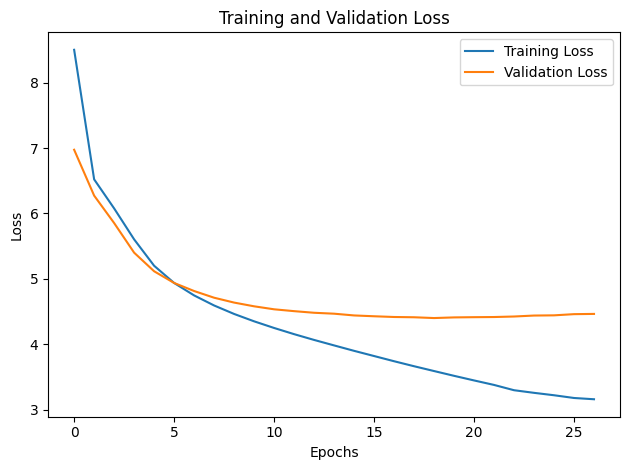

In [160]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

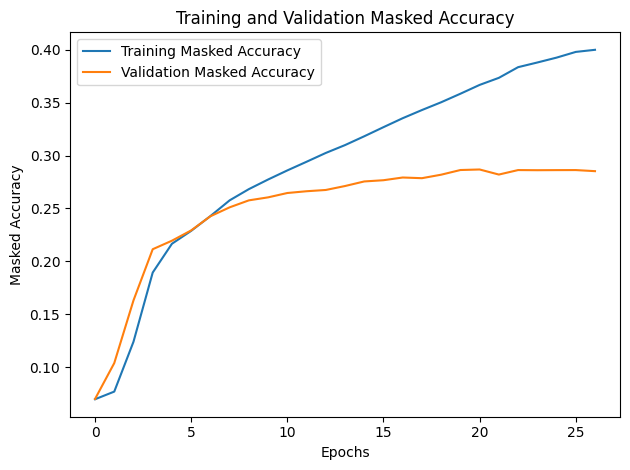

In [161]:
masked_accuracy = history.history['masked_accuracy']
val_masked_accuracy = history.history['val_masked_accuracy']

plt.plot(masked_accuracy, label='Training Masked Accuracy')
plt.plot(val_masked_accuracy, label='Validation Masked Accuracy')
plt.title('Training and Validation Masked Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Masked Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [162]:
model.load_weights("best_samsum_transformer.weights.h5")

print("Best model weights loaded successfully.")

Best model weights loaded successfully.


In [163]:
test_results = model.evaluate(
    x=(X_test, decoder_test),
    y=y_test,
    batch_size=64,
    return_dict=True,
    verbose=1
)

print("\nTest Evaluation:")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - loss: 4.4292 - masked_accuracy: 0.2856

Test Evaluation:
loss: 4.4292
masked_accuracy: 0.2856


In [164]:
def generate_summary(encoder_sequence, max_length=MAX_DECODER_LENGTH):

    encoder_sequence = tf.convert_to_tensor(
        encoder_sequence[None, :],
        dtype=tf.int32
    )

    decoder_sequence = tf.constant([[2]], dtype=tf.int32)

    for _ in range(max_length - 1):

        logits = model(
            (encoder_sequence, decoder_sequence),
            training=False
        )

        next_token_logits = logits[:, -1, :]

        blocked_logits = tf.fill(
            [1, 3],
            tf.constant(-1e9, dtype=next_token_logits.dtype)
        )

        next_token_logits = tf.concat(
            [blocked_logits, next_token_logits[:, 3:]],
            axis=-1
        )

        next_token = tf.argmax(
            next_token_logits,
            axis=-1,
            output_type=tf.int32
        )

        decoder_sequence = tf.concat(
            [decoder_sequence, next_token[:, tf.newaxis]],
            axis=1
        )

        if next_token[0].numpy() == 3:
            break

    return decoder_sequence.numpy()[0]

In [165]:
def decode_summary(token_ids):
    return t5_tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    )

In [166]:
sample_index = 0

generated_ids = generate_summary(X_test[sample_index])

generated_summary = decode_summary(generated_ids)

reference_summary = test_df["summary"].iloc[sample_index]

print("ORIGINAL DIALOGUE:\n")
print(test_df["dialogue"].iloc[sample_index])

print("\nREFERENCE SUMMARY:\n")
print(reference_summary)

print("\nGENERATED SUMMARY:\n")
print(generated_summary)

ORIGINAL DIALOGUE:

Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I don't know him well
Hannah: <file_gif>
Amanda: Don't be shy, he's very nice
Hannah: If you say so..
Hannah: I'd rather you texted him
Amanda: Just text him 🙂
Hannah: Urgh.. Alright
Hannah: Bye
Amanda: Bye bye

REFERENCE SUMMARY:

Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.

GENERATED SUMMARY:

The party is at the party. She will be late. She will be there. They will be there. They will be there. They will be there. They will be there.. They'll be there... They'll be there will be there...... They will be there will be there's going to be there......


In [168]:
from rouge_score import rouge_scorer
import numpy as np

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

scores = []

NUM_EVAL_SAMPLES = 100

for i in range(NUM_EVAL_SAMPLES):

    generated_ids = generate_summary(X_test[i])

    prediction = decode_summary(generated_ids)

    reference = test_df["summary"].iloc[i]

    result = scorer.score(reference, prediction)

    scores.append({
        metric: result[metric].fmeasure
        for metric in ["rouge1", "rouge2", "rougeL"]
    })

print("\nROUGE Results:")

for metric in ["rouge1", "rouge2", "rougeL"]:

    average_score = np.mean([
        score[metric] for score in scores
    ])

    print(f"{metric}: {average_score:.4f}")


ROUGE Results:
rouge1: 0.1294
rouge2: 0.0211
rougeL: 0.1090
